<a href="https://colab.research.google.com/github/Hongo777/001_Operations_research_n_staff/blob/main/0010_Ass.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
#we create a function to return :
    #solar altitude = a
    #solar azmuth angle = z
    #wall solar azmuth angle = z_wall
    # cos(i) = this the cosine of the angel of incicence of strike on the wall
#input to our function:
    #solar noon
    #n = day of the year
    #L = lattitude
    #Orie = orientation angle with zero degrees means facing the sun and equal to solar azmuth angle z. And its given as in anticlocwise is positive
    #dell = angle between  the surface to the earth horizontal

def get_a_z_zWall_cosi_GvnTNLODell(noon,n,L,Orie,dell): #for tilted at angle dell,

    #you can let isntead of iniput T, input solar noon time such that H = 15* ( T -solar noon)
    T = np.arange(24)
    H = np.deg2rad(  (15 * (T-noon ) ) )
    d = np.deg2rad(  ( 23.45 *  np.sin( np.deg2rad( 360 * (284 + n ) / 365) ) ) )
    Latitude = np.deg2rad(L)
    dell = np.deg2rad(dell) #dell = surface that is tilted at an angle dell
    #return a,z in degrees
    a =     np.rad2deg(  np.arcsin(  np.sin( d ) * np.sin( Latitude )  + np.cos ( d ) * np.cos( Latitude ) * np.cos ( H )  ) )
    a = np.maximum(0, a)
    z = np.rad2deg(  np.arctan(   np.sin ( H ) /  ( np.sin(Latitude) * np.cos(H) - np.cos(Latitude) * np.tan(d) ) ) )
    z[a == 0 ] = 90 #90 0r -90 means night or shadow

    z_wall = z - Orie
    z_wall[a == 0 ] = 90 #90 0r -90 means night or shadow
    z_wall = np.clip(z_wall, -90, 90)

    # now we create: cosi = sin(a) * cos( dell) + cos(a) * cos(z_wall) * sin(dell)
    cos_i = np.sin(  np.deg2rad(a)  ) * np.cos(dell) +  np.cos( np.deg2rad(a) ) * np.cos(np.deg2rad(z_wall)) * np.sin(dell)
    cos_i[a ==0 ] = 0
    return a,z,z_wall,cos_i

# also notice how this code accnts for long nights on lower hemishere during n = 365 etc,,use this to interprate Orientation ??


## ass1

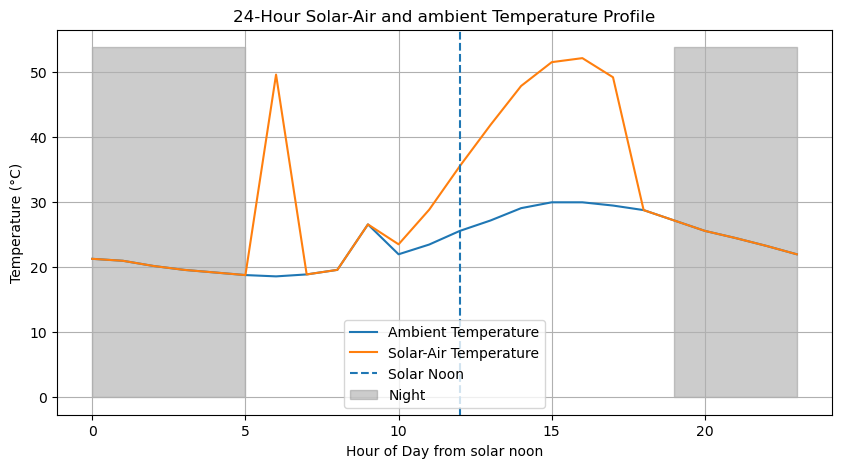

(47.9055169300767, 29.1)

In [ ]:
T_b,T_d = 0.697,1.51
E_sc = 1367
n= 233
Dell = 90 # for vetical wall
E_sDrOverH_o = 0 # for vertical wall and 4 for roof
rho_g = 0.25
h_o = 28
L = 40
Orie = 30
noon = 12


temp_ambient = np.array( [21.3,
    21, 20.2, 19.6, 19.2, 18.8, 18.6,
    18.9, 19.6, 26.6, 22, 23.5, 25.6,
    27.2, 29.1, 30, 30, 29.5, 28.8,
    27.2, 25.6, 24.5, 23.3, 22
                ] )
T = np.arange(24)

TwoPM = np.array([2])# hours before sun noon
T_ambientTpm = np.array([29.1]) # must be same lenght as T



geomoetry = get_a_z_zWall_cosi_GvnTNLODell(noon,n,L,Orie,Dell) #we make use of our fuction creted above
sin_B =  np.sin( np.deg2rad( geomoetry[0]))
m = 1 / (  sin_B + 0.50572 * ((6.07995 + geomoetry[0])** -1.6364) )
E_o = E_sc * (1 + 0.033 * np.cos(np.deg2rad(360*(n-3)/365)))

# RADIATION MODELS (ASHRAE)
            # T_b,T_d coild be changing throughout the day??  pdf page of ASHRAE pg282
ab = 1.454 - 0.406*T_b - 0.268*T_d + 0.021*T_b*T_d
ad = 0.507 + 0.205*T_b - 0.080*T_d - 0.99*(T_d**2) # check


E_b = E_o * np.exp(-T_b * (m**ab))
E_d = E_o * np.exp(-T_d * (m**ad)) #confirm this
#E_d = 259.7

E_tb = E_b * geomoetry[3]
# Diffuse factor Y
Y = np.maximum(0.45, 0.55 + 0.437*geomoetry[3] + 0.313*(geomoetry[3]**2))
E_td = E_d * Y

# Ground-reflected radiation
E_tr = (E_b*sin_B + E_d) * rho_g * ((1 - np.cos( np.deg2rad(Dell) ))/2)

q_sol = geomoetry[3] * (  E_tr + E_tb + E_td)

#T_sa = T_ambientTpm + q_sol / h_o
T_sa = temp_ambient + q_sol / h_o - E_sDrOverH_o

#Plot
plt.figure(figsize=(10,5))
plt.plot(T, temp_ambient, label="Ambient Temperature")
plt.plot(T, T_sa, label="Solar-Air Temperature")

# Noon line
plt.axvline(noon, linestyle='--', label="Solar Noon")

# Night shading
plt.fill_between(T, 0, plt.ylim()[1],
                 where=(geomoetry[0] == 0),
                 color='gray', alpha=0.4, label='Night')

plt.xlabel("Hour of Day from solar noon")
plt.ylabel("Temperature (°C)")
plt.title("24-Hour Solar-Air and ambient Temperature Profile")
plt.legend()
plt.grid(True)
plt.show()

T_sa[14],temp_ambient[14] #get values for 2pm

In [ ]:
geomoetry

(array([ 0.        ,  0.        ,  0.        ,  0.        ,  0.        ,
         0.        ,  7.52412578, 18.96878908, 30.39338723, 41.39606831,
        51.30146165, 58.80061146, 61.75412053, 58.80061146, 51.30146165,
        41.39606831, 30.39338723, 18.96878908,  7.52412578,  0.        ,
         0.        ,  0.        ,  0.        ,  0.        ]),
 array([ 90.        ,  90.        ,  90.        ,  90.        ,
         90.        ,  90.        ,  80.94352781, -89.58652492,
        -79.40469142, -67.34585023, -51.53107062, -29.28515705,
          0.        ,  29.28515705,  51.53107062,  67.34585023,
         79.40469142,  89.58652492, -80.94352781,  90.        ,
         90.        ,  90.        ,  90.        ,  90.        ]),
 array([ 90.        ,  90.        ,  90.        ,  90.        ,
         90.        ,  90.        ,  50.94352781, -90.        ,
        -90.        , -90.        , -81.53107062, -59.28515705,
        -30.        ,  -0.71484295,  21.53107062,  37.34585023,
    

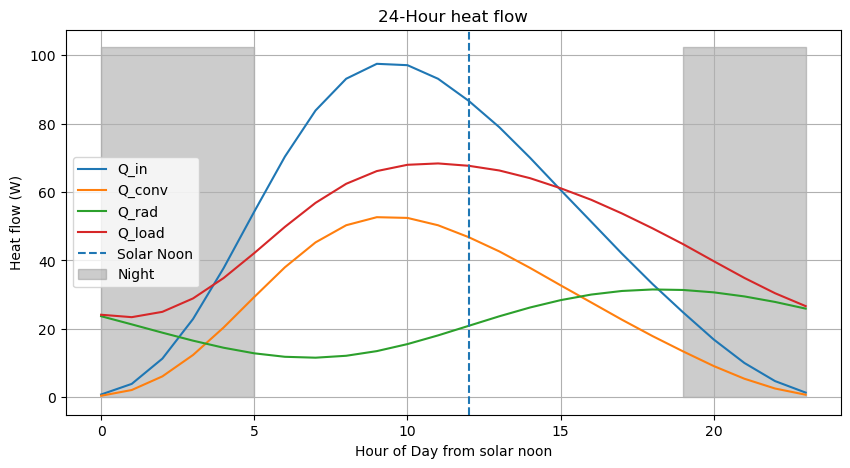

In [ ]:
# refer to this file: TUTORIAL 3 SOLUTIONS
U_o = 0.58 # heat tranfer coeficcient in W/m^2K
A = 14 # area of the wall in m^2
T_r = 23 # room temperature in degrees degrees celsius



# check : In the context of the ASHRAE Conduction Time Series (CTS) or Radiant Time Series (RTS) method, the "hour" refers to hours past solar noon for the purpose of calculating solar heat gain, not past midnight.??
# read these from ASHRAE
ct = [1,1,2,5,8,9,9,9,8,7,7,6,5, 4,4,3,3,2,2,2,1,1,1,0] # wall conduction time sreies wall number 14, brick, insulation board
ct = ct[ (len(ct) - noon) :  ] + ct[ : (len(ct) - noon)   ]
C_n = np.array (ct)

cf = 0.54 #convection fraction
rf = 0.46 #radiactive fraction
rt =  [33, 16, 10,7,5,4,3,3,2,2,2,2,1, 1,1,1,1,1,1,1,1,1,1,1]   # Non solar RTS for conduction heat flow: medium construction, no carpet,50% glass
rt = ct[ (len(rt) - noon) :  ] + ct[ : (len(rt) - noon)   ]
r_theta = np.array (rt)


#calculations
Q_e = A * U_o * ( T_sa - T_r ) # rate of heat gain at outer surface, like table 2

Q_theta = []
for i in range(len(Q_e)):
    Q_ei = []
    for j in range( len(Q_e[:(i+1)])  ): #for upto 0i00h
        Q_ei.append(Q_e[: (i+1) ][ (len(Q_e[: (i+1)] ) -1  -j)])

    for j in range( len(Q_e[(i+1):])  ):
        Q_ei.append(Q_e[ (i+1) :][ (len(Q_e[(i+1):] ) -1  -j)])
    Q_theta.append(sum ( Q_ei * C_n)  /100 ) # for the ouptuts of table four


Q_rtheta = [] # radiant cooling load, Q_r for hour theta
Cooling_load = []
Q_covection = []
for i in range(len(Q_theta)):
    Q_ini = []
    for j in range( len(Q_theta[:(i+1)])  ): #for upto 0i00h like 1500h
        Q_ini.append(Q_theta[: (i+1) ][ (len(Q_theta[: (i+1)] ) -1  -j)])

    for j in range( len(Q_theta[(i+1):])  ):
        Q_ini.append(Q_theta[ (i+1) :][ (len(Q_theta[(i+1):] ) -1  -j)])
    Q_rtheta.append( rf * sum(Q_ini * r_theta) /100   )
    Q_covection.append( cf * Q_theta[i] )
    Cooling_load.append( Q_covection[i]  +  Q_rtheta[i]     ) # this Q_convection + Q_radiation.....and Q_in = Q_theta??

#Plot
plt.figure(figsize=(10,5))
plt.plot(T, Q_theta, label="Q_in")
plt.plot(T, Q_covection, label="Q_conv")
plt.plot(T, Q_rtheta, label="Q_rad")
plt.plot(T, Cooling_load, label="Q_load")

# Noon line
plt.axvline(noon, linestyle='--', label="Solar Noon")


# Night shading
plt.fill_between(T, 0, plt.ylim()[1],
                 where=(geomoetry[0] == 0),
                 color='gray', alpha=0.4, label='Night')

plt.xlabel("Hour of Day from solar noon")
plt.ylabel("Heat flow (W)")
plt.title("24-Hour heat flow")
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
# run this cell then run the cell above in oreder to go with the instructos T_sa
# the instructors T_sa
T_sa = np.array ([  21.3,
                    21, 20.2,
                     19.6,19.2,
                     18.8,19.8,
                     21.4,21.7,
                     26,30.4,
                     36.3,41.9,

                   45.7,47.9,
                  47.0,43.1,
                  37.3,32,
                  27.2,25.6,
                  24.5,23.3,
                  22] )

## ass2

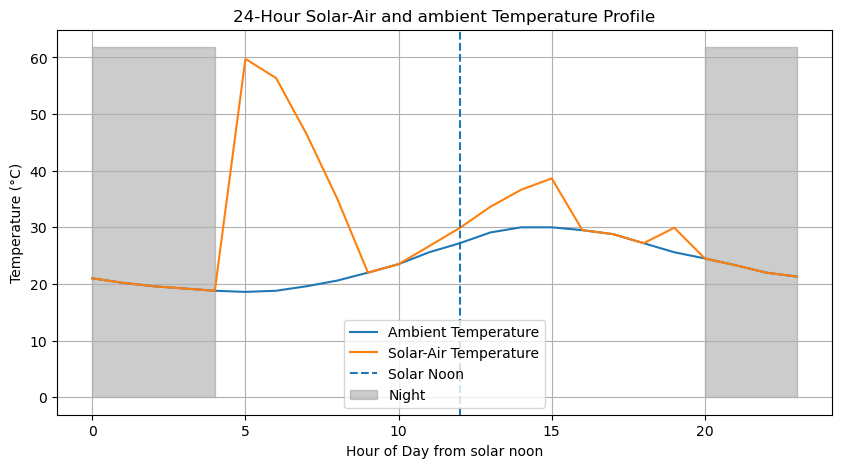

(29.500000000000004, 29.5)

In [ ]:
T_b,T_d = 0.337, 2.36
E_sc = 1367
n= 163  # June 12
Dell = 90 # for vetical wall
E_sDrOverH_o = 0 # for vertical wall and 4 for roof
rho_g = 0.2
h_o = 28
L = 35
Orie = 20
noon = 12
#how do we use the solar absorbitivity = 0.75

#ambient temp need to be arranged from noon...not realy
temp_ambient = np.array(  [21, 20.2, 19.6, 19.2, 18.8, 18.6, 18.8, 19.6, 20.6, 22, 23.5, 25.6,
         27.2, 29.1, 30, 30, 29.5, 28.8, 27.2, 25.6, 24.5, 23.3, 22, 21.3] )




T = np.arange(24)

TwoPM = np.array([2])# hours before sun noon
T_ambientTpm = np.array([29.1]) # must be same lenght as T



geomoetry = get_a_z_zWall_cosi_GvnTNLODell(noon,n,L,Orie,Dell) #we make use of our fuction creted above
sin_B =  np.sin( np.deg2rad( geomoetry[0]))
m = 1 / (  sin_B + 0.50572 * ((6.07995 + geomoetry[0])** -1.6364) )
E_o = E_sc * (1 + 0.033 * np.cos(np.deg2rad(360*(n-3)/365)))

# RADIATION MODELS (ASHRAE)
            # T_b,T_d coild be changing throughout the day??  pdf page of ASHRAE pg282
ab = 1.454 - 0.406*T_b - 0.268*T_d + 0.021*T_b*T_d
ad = 0.507 + 0.205*T_b - 0.080*T_d - 0.99*(T_d**2) # check


E_b = E_o * np.exp(-T_b * (m**ab))
E_d = E_o * np.exp(-T_d * (m**ad)) #confirm this
#E_d = 259.7

E_tb = E_b * geomoetry[3]
# Diffuse factor Y
Y = np.maximum(0.45, 0.55 + 0.437*geomoetry[3] + 0.313*(geomoetry[3]**2))
E_td = E_d * Y

# Ground-reflected radiation
E_tr = (E_b*sin_B + E_d) * rho_g * ((1 - np.cos( np.deg2rad(Dell) ))/2)

q_sol = geomoetry[3] * (  E_tr + E_tb + E_td)

#T_sa = T_ambientTpm + q_sol / h_o
T_sa = temp_ambient + q_sol / h_o - E_sDrOverH_o

#Plot
plt.figure(figsize=(10,5))
plt.plot(T, temp_ambient, label="Ambient Temperature")
plt.plot(T, T_sa, label="Solar-Air Temperature")

# Noon line
plt.axvline(noon, linestyle='--', label="Solar Noon")

# Night shading
plt.fill_between(T, 0, plt.ylim()[1],
                 where=(geomoetry[0] == 0),
                 color='gray', alpha=0.4, label='Night')

plt.xlabel("Hour of Day from solar noon")
plt.ylabel("Temperature (°C)")
plt.title("24-Hour Solar-Air and ambient Temperature Profile")
plt.legend()
plt.grid(True)
plt.show()

T_sa[16],temp_ambient[16] #get values for 4pm

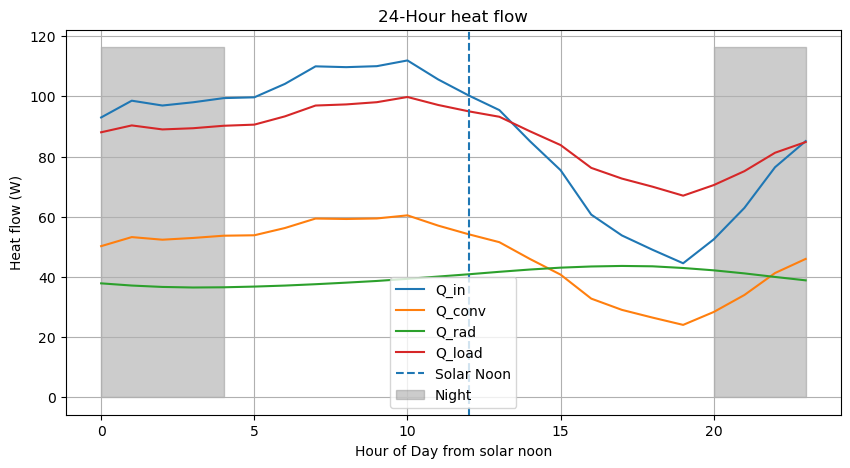

(60.691398961344085, 99.79482064976109, 10)

In [ ]:
# refer to this file: TUTORIAL 3 SOLUTIONS
U_o = 0.628 # heat tranfer coeficcient in W/m^2K
A = 24 # area of the wall in m^2
T_r = 24 # room temperature in degrees degrees celsius

# read these from ASHRAE
ct =  [2, 2, 2, 4, 5, 6, 6, 7, 7, 6, 6, 6, 5, 5, 5, 4, 4, 4, 3, 3, 3, 2, 2, 1]  # wall conduction time sreies wall number 14, brick, insulation board
ct = ct[ (len(ct) - noon) :  ] + ct[ : (len(ct) - noon)   ]
C_n = np.array (ct)


cf = 0.54 #convection fraction
rf = 0.46 #radiactive fraction
rt =  [50, 18, 10, 6, 4, 3, 2, 1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]   # Non solar RTS for conduction heat flow: medium construction, no carpet,50% glass
rt = ct[ (len(rt) - noon) :  ] + ct[ : (len(rt) - noon)   ]
r_theta = np.array (rt)


#calculations
Q_e = A * U_o * ( T_sa - T_r ) # rate of heat gain at outer surface, like table 2

Q_theta = [] #Conduction heat gain??
for i in range(len(Q_e)):
    Q_ei = []
    for j in range( len(Q_e[:(i+1)])  ): #for upto 0i00h
        Q_ei.append(Q_e[: (i+1) ][ (len(Q_e[: (i+1)] ) -1  -j)])

    for j in range( len(Q_e[(i+1):])  ):
        Q_ei.append(Q_e[ (i+1) :][ (len(Q_e[(i+1):] ) -1  -j)])
    Q_theta.append(sum ( Q_ei * C_n)  /100 ) # for the ouptuts of table four


Q_rtheta = [] # radiant cooling load, Q_r for hour theta
Cooling_load = []
Q_covection = []
for i in range(len(Q_theta)):
    Q_ini = []
    for j in range( len(Q_theta[:(i+1)])  ): #for upto 0i00h like 1500h
        Q_ini.append(Q_theta[: (i+1) ][ (len(Q_theta[: (i+1)] ) -1  -j)])

    for j in range( len(Q_theta[(i+1):])  ):
        Q_ini.append(Q_theta[ (i+1) :][ (len(Q_theta[(i+1):] ) -1  -j)])
    Q_rtheta.append( rf * sum(Q_ini * r_theta) /100   )
    Q_covection.append( cf * Q_theta[i] )
    Cooling_load.append( Q_covection[i]  +  Q_rtheta[i]     ) # this Q_convection + Q_radiation.....and Q_in = Q_theta??

#Plot
plt.figure(figsize=(10,5))
plt.plot(T, Q_theta, label="Q_in")
plt.plot(T, Q_covection, label="Q_conv")
plt.plot(T, Q_rtheta, label="Q_rad")
plt.plot(T, Cooling_load, label="Q_load")


# Noon line
plt.axvline(noon, linestyle='--', label="Solar Noon")

# Night shading
plt.fill_between(T, 0, plt.ylim()[1],
                 where=(geomoetry[0] == 0),
                 color='gray', alpha=0.4, label='Night')

plt.xlabel("Hour of Day from solar noon")
plt.ylabel("Heat flow (W)")
plt.title("24-Hour heat flow")
plt.legend()
plt.grid(True)
plt.show()

#cooling load due to heat conduction through the wall at 4 p.m. and maximaumcooling load
Q_theta[16],np.max(Cooling_load), np.argmax(Cooling_load)

In [ ]:
Q_e

array([-45.216     , -57.2736    , -66.3168    , -72.3456    ,
       -78.3744    , 538.7771326 , 487.76111322, 337.92861585,
       166.35761832, -30.144     ,  -7.536     ,  40.54634468,
        89.00903867, 145.23511613, 190.49998695, 220.61695039,
        82.896     ,  72.3456    ,  48.2304    ,  89.2744943 ,
         7.536     , -10.5504    , -30.144     , -40.6944    ])

## trial codes Ignore things below this

![image.png](attachment:8dea841f-f9cc-4ef4-9c75-2efb8df12026.png)
![image.png](attachment:6dfd9391-699b-4c52-9bbd-b5cf961f9bb8.png)

In [ ]:
data = [1, 2, 3, 4, 5, 6]
index = 3  # The value at this index is 4

# Option A: Include the element at the index [4, 3, 2, 1]
result_inclusive = data[index::-1]

# Option B: Exclude the element at the index [3, 2, 1]
result_exclusive = data[index-1::-1]

print(f"Inclusive: {result_inclusive}")
print(f"Exclusive: {result_exclusive}")


Inclusive: [4, 3, 2, 1]
Exclusive: [3, 2, 1]


In [ ]:
import numpy as np

arr = np.array([1, 2, 3, 4, 5, 6])
idx = 3

# Slice backward from index 3
backward_arr = arr[idx::-1]

print(f"NumPy result: {backward_arr}")


NumPy result: [4 3 2 1]


In [ ]:
import numpy as np

arr1 = np.array([1, 2, 3])
arr2 = np.array([4, 5, 6])

# Join them together
result = np.concatenate((arr1, arr2))
result


array([1, 2, 3, 4, 5, 6])

In [ ]:
#If you just want to add values to the end of an array, np.append() works similarly to the list method, but remember that it returns a new array rather than modifying the original one in place
result = np.append(arr1, arr2)
result

array([1, 2, 3, 4, 5, 6])